# Arm comparison across model runs
Scores each run from its stored predictions with the exact rules in `run_eval.py`
(`matches()`, `arm_predictions()`), so numbers agree with `experiments.csv`.
Accuracy is over the **5 core fields** (role, company, location, job_id, pay).
Edit `RUNS` / `SPLIT` in the first cell, then Run All.

In [7]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Notebook cwd is eval/ (fall back to ./eval when run from the repo root).
HERE = os.getcwd()
if os.path.basename(HERE) != "eval":
    HERE = os.path.join(HERE, "eval")
sys.path[:0] = [HERE, os.path.dirname(HERE)]  # eval/ for run_eval, repo root for parse
import run_eval as R  # reuse the exact scoring rules

# ---- Config: edit these ----
RUNS = {  # run folder -> short label for plots
    "q25vl3b_v2": "Qwen2.5-VL 3B",
    "q25vl7b": "Qwen2.5-VL 7B",
    "q3vl8b": "Qwen3-VL 8B",
    "q3vl8b_or": "Qwen3-VL 8B (OpenRouter)",
    "q3vl4b": "Qwen3-VL 4B",
}
SPLIT = "test"  # dev | test | all  (test = final numbers; use dev while tuning)
KEY = "png"     # labels column the run's file names join on
CORE = R.CORE
ARMS = ["regex", "vlm", "merge", "router", "oracle"]
VLM_ARMS = ["vlm", "merge", "router", "oracle"]  # regex is the same for every run
ARM_COLORS = {"vlm": "#4C72B0", "merge": "#55A868", "router": "#C44E52", "oracle": "#BBBBBB"}

In [8]:
def score_run(run):
    """Score one run: a long DataFrame, one row per (file, arm) with 0/1 per core field + latency."""
    labels = R.load_labels(KEY)
    rows = []
    for rec in R.load_jsonl(os.path.join(HERE, "runs", run, "predictions.jsonl")):
        lab = labels.get(rec["file"])
        if "vlm" not in rec or lab is None or not lab.get("verified"):
            continue
        if SPLIT != "all" and lab.get("split") != SPLIT:
            continue
        arms = R.arm_predictions(rec)
        # A failed VLM call counts as wrong for VLM-derived arms (same as run_eval.score).
        for arm in ("vlm", "merge", "router"):
            arms.setdefault(arm, ({}, rec["regex"]["latency_s"] + rec["vlm"]["latency_s"]))
        ok = {arm: {k: int(R.matches(k, fields.get(k), lab)) for k in CORE}
              for arm, (fields, _) in arms.items()}
        ok["oracle"] = {k: int(ok["regex"][k] or ok["vlm"][k]) for k in CORE}  # upper bound
        for arm, per in ok.items():
            rows.append({"run": run, "file": rec["file"], "arm": arm, **per,
                         "all_core": int(all(per.values())),
                         "mean_field": float(np.mean(list(per.values()))),  # avg of the 5 field scores
                         "latency": arms[arm][1] if arm in arms else np.nan})  # oracle has none
    return pd.DataFrame(rows)


df = pd.concat([score_run(r) for r in RUNS], ignore_index=True)
docs = df.groupby("run")["file"].nunique().reindex(list(RUNS))
print(f"split={SPLIT}, docs scored per run:\n{docs.to_string()}")
if docs.nunique() > 1:
    print("WARNING: runs cover different doc counts (partial run?): numbers are not comparable")

split=test, docs scored per run:
run
q25vl3b_v2    62
q25vl7b       62
q3vl8b        62
q3vl8b_or     62
q3vl4b        62


## Summary table
Accuracy in %, latency in seconds (p50 / p95). Latency is from `--test` mode (regex + VLM run at once;
OpenRouter includes network time), so treat it as relative, not as live latency.

In [9]:
g = df.groupby(["run", "arm"])
summary = g.agg(n=("file", "size"), all_core=("all_core", "mean"), mean_field=("mean_field", "mean"),
                p50=("latency", lambda s: s.quantile(0.5)), p95=("latency", lambda s: s.quantile(0.95)),
                **{k: (k, "mean") for k in CORE})
summary[["all_core", "mean_field", *CORE]] *= 100
# Keep regex once (identical across runs), then each run's VLM-derived arms.
order = [(next(iter(RUNS)), "regex")] + [(r, a) for r in RUNS for a in VLM_ARMS]
table = summary.loc[order].round(1)
table.index = ["regex (all runs)"] + [f"{RUNS[r]} | {a}" for r in RUNS for a in VLM_ARMS]
table

,n,all_core,mean_field,p50,p95,role,company,location,job_id,pay
regex (all runs),62,0.0,20.0,0.4,0.9,9.7,0.0,27.4,43.5,19.4
Qwen2.5-VL 3B | vlm,62,3.2,44.5,7.4,8.1,64.5,41.9,72.6,24.2,19.4
Qwen2.5-VL 3B | merge,62,3.2,44.8,7.4,8.1,64.5,41.9,72.6,24.2,21.0
Qwen2.5-VL 3B | router,62,3.2,44.5,7.8,8.6,64.5,41.9,72.6,24.2,19.4
Qwen2.5-VL 3B | oracle,62,3.2,54.2,NaN,NaN,66.1,41.9,74.2,67.7,21.0
Qwen2.5-VL 7B | vlm,62,11.3,62.6,13.5,16.1,79.0,56.5,79.0,80.6,17.7
Qwen2.5-VL 7B | merge,62,11.3,60.3,13.5,16.1,79.0,56.5,79.0,67.7,19.4
Qwen2.5-VL 7B | router,62,11.3,62.6,13.9,16.6,79.0,56.5,79.0,80.6,17.7
Qwen2.5-VL 7B | oracle,62,11.3,63.9,NaN,NaN,80.6,56.5,79.0,82.3,21.0
Qwen3-VL 8B | vlm,62,11.3,61.6,8.9,12.0,77.4,51.6,75.8,83.9,19.4


## 1. Doc pass rate (all 5 core fields correct)
Bars are the VLM-derived arms per run with 95% Wilson intervals; the dashed line is the regex baseline.

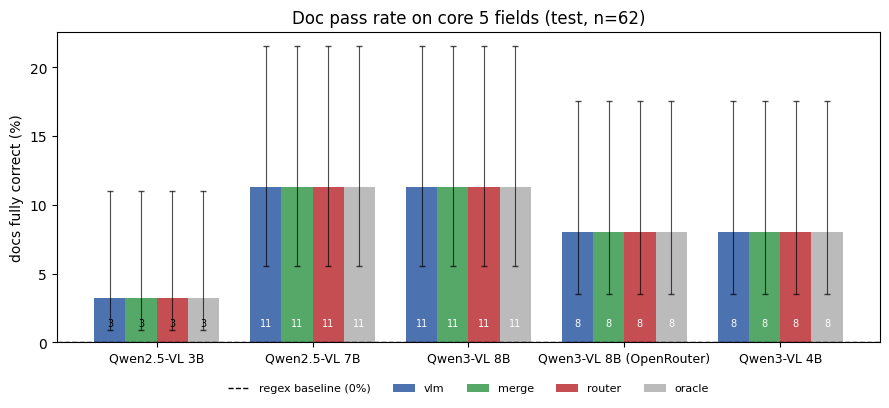

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.2
for i, arm in enumerate(VLM_ARMS):
    ys, errs = [], [[], []]
    for r in RUNS:
        s = summary.loc[(r, arm)]
        k, n = int(round(s.all_core * s.n / 100)), int(s.n)
        lo, hi = R.wilson(k, n)
        ys.append(s.all_core); errs[0].append(s.all_core - lo); errs[1].append(hi - s.all_core)
    xs = np.arange(len(RUNS)) + (i - 1.5) * width
    ax.bar(xs, ys, width, yerr=errs, capsize=2, color=ARM_COLORS[arm], label=arm,
           error_kw={"lw": 0.8, "alpha": 0.7})
    for x, y in zip(xs, ys):
        ax.text(x, 1, f"{y:.0f}", ha="center", va="bottom", fontsize=7, color="white" if y > 8 else "black")
base = summary.loc[(next(iter(RUNS)), "regex")].all_core
ax.axhline(base, ls="--", color="black", lw=1, label=f"regex baseline ({base:.0f}%)")
ax.set_xticks(range(len(RUNS))); ax.set_xticklabels(RUNS.values(), fontsize=9)
ax.set_ylabel("docs fully correct (%)"); ax.set_ylim(0, max(ax.get_ylim()[1], 10))  # auto-fit to the data
ax.set_title(f"Doc pass rate on core 5 fields ({SPLIT}, n={int(docs.iloc[0])})")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Per-field accuracy and latency (matrix)
One row per run and arm. Left: accuracy % for each core field and for all 5 correct (green = high).
Right: latency in seconds (green = within the p50 gate in `run_eval.py`, red = slow).
Regex is shown once since it is the same for every run; oracle has no latency (it is an upper bound, not a pipeline).
Latency is from `--test` mode (regex and VLM run together; OpenRouter includes network time), so read it as relative.

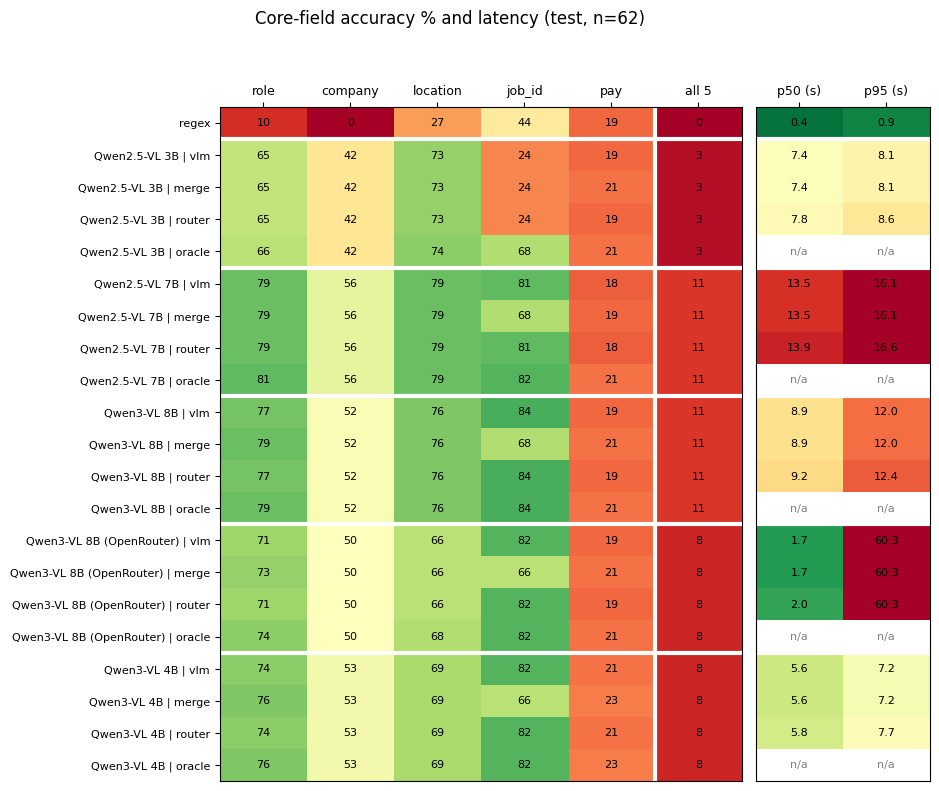

In [11]:
cols = CORE + ["all_core"]
acc = summary.loc[order, cols]
lat = summary.loc[order, ["p50", "p95"]]
labels_y = ["regex"] + [f"{RUNS[r]} | {a}" for r in RUNS for a in VLM_ARMS]

fig, (ax, axl) = plt.subplots(1, 2, figsize=(10, 0.32 * len(order) + 1.4), sharey=True,
                              gridspec_kw={"width_ratios": [len(cols), 2], "wspace": 0.04})
ax.imshow(acc.values, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
# Latency: colored on a 0 to 3x-gate scale so "under the gate" reads as green.
axl.imshow(lat.values, cmap="RdYlGn_r", vmin=0, vmax=3 * R.MAX_P50_S, aspect="auto")

for a_, tbl, heads, fmt in [(ax, acc, ["role", "company", "location", "job_id", "pay", "all 5"], "{:.0f}"),
                            (axl, lat, ["p50 (s)", "p95 (s)"], "{:.1f}")]:
    a_.set_xticks(range(len(heads))); a_.set_xticklabels(heads, fontsize=9)
    a_.xaxis.tick_top()
    for i in range(tbl.shape[0]):
        for j in range(tbl.shape[1]):
            v = tbl.values[i, j]
            a_.text(j, i, "n/a" if np.isnan(v) else fmt.format(v), ha="center", va="center",
                    fontsize=8, color="gray" if np.isnan(v) else "black")
    for i in range(1, len(order), len(VLM_ARMS)):  # separator above each run's block
        a_.axhline(i - 0.5, color="white", lw=3)
    a_.axvline(len(heads) - 1.5, color="white", lw=3) if a_ is ax else None  # set "all 5" apart
ax.set_yticks(range(len(order))); ax.set_yticklabels(labels_y, fontsize=8)
axl.tick_params(left=False)
fig.subplots_adjust(left=0.27, right=0.98, top=0.86, bottom=0.03)  # room for the row labels
fig.suptitle(f"Core-field accuracy % and latency ({SPLIT}, n={int(docs.iloc[0])})")
plt.show()

## Config check
Settings should be identical across runs except for the model/backend.

In [12]:
import json
meta = {RUNS[r]: {k: v for k, v in json.load(open(os.path.join(HERE, "runs", r, "meta.json"))).items()
                  if k not in ("prompt", "started")} for r in RUNS}
pd.DataFrame(meta)

,Qwen2.5-VL 3B,Qwen2.5-VL 7B,Qwen3-VL 8B,Qwen3-VL 8B (OpenRouter),Qwen3-VL 4B
backend,local,local,local,paid,local
model,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,mlx-community/Qwen2.5-VL-7B-Instruct-4bit,mlx-community/Qwen3-VL-8B-Instruct-4bit,qwen/qwen3-vl-8b-instruct,mlx-community/Qwen3-VL-4B-Instruct-4bit
git_commit,5ac504a,5ac504a,5ac504a,5ac504a,780105e
prompt_sha1,4fc8796fa6,4fc8796fa6,4fc8796fa6,4fc8796fa6,4fc8796fa6
max_pixels,1048576,1048576,1048576,1048576,1048576
crop_top,1.0,1.0,1.0,1.0,1.0
max_tokens,160,160,160,160,160
note,frozen v1,frozen v1,frozen v1,frozen v1,frozen v1
